In [1]:
#read the data files
from pathlib import Path
import pandas as pd
DATA_DIR=Path.cwd()/"data"/"case1"

#create the 16 feature columns
import numpy as np
MAX_DEGREE=3

#fit linear regression
from sklearn.linear_model import LinearRegression

#feature selection
import itertools
from sklearn.model_selection import KFold, cross_val_score
from sklearn.linear_model import LassoCV
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
RANDOM_SEED=42

#report the P(formula) and errors
from scipy import stats

#plot errors vs flow
import matplotlib.pyplot as plt

# Looking at the data

In [2]:
#loading the data
train=pd.read_csv(DATA_DIR/"train1.csv")
test=pd.read_csv(DATA_DIR/"test1.csv")

data_checks=pd.DataFrame({
    name: {
        "rows": len(df),
        "pumps": df.pump_id.nunique(),
        "operating states": ", ".join(df.operating_state.unique()),
        "missing values": int(df.isna().sum().sum()),
        "flow < 0": int((df.flow_m3_h<0).sum()),
        "power <= 0": int((df.power_w<=0).sum()),
    }
    for name, df in [("train1", train), ("test1", test)]
})
print(data_checks)
#Columns used: ['pump_id', 'elapsed_s', 'operating_state', 'speed_rpm', 'power_w', 'inlet_pressure_bar', 'outlet_pressure_bar', 'flow_m3_h']
#NO CLEANING NEEDED!

                  train1   test1
rows                 480     120
pumps                  1       1
operating states  stable  stable
missing values         0       0
flow < 0               0       0
power <= 0             0       0


In [3]:
print(train[["speed_rpm", "flow_m3_h", "power_w"]].describe().round(1))
#std=standard deviation-how spread out the values are

       speed_rpm  flow_m3_h  power_w
count      480.0      480.0    480.0
mean      3167.6       18.8    703.5
std        993.3       13.1    553.3
min       1494.2        0.4     63.2
25%       2358.8        8.0    227.3
50%       3221.1       16.5    551.4
75%       4073.2       27.4   1042.0
max       4813.2       56.8   2201.7


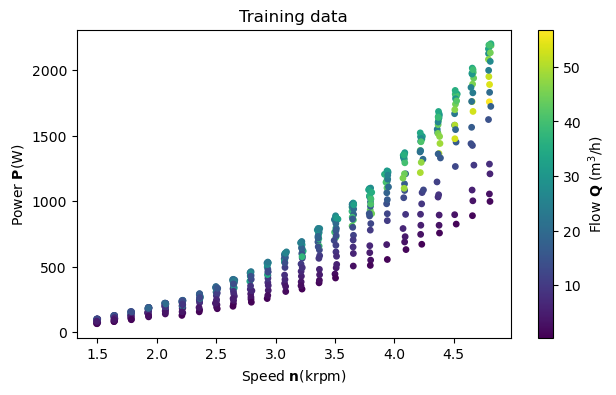

In [4]:
fig, ax=plt.subplots(figsize=(7, 4))
points=ax.scatter(train.speed_rpm/1000, train.power_w, c=train.flow_m3_h, cmap="viridis", s=15)
fig.colorbar(points, label=r"Flow $\mathbf{Q}$ (m$^3$/h)")
ax.set_xlabel(r"Speed $\mathbf{n}$(krpm)")
ax.set_ylabel(r"Power $\mathbf{P}$(W)")
ax.set_title("Training data")
plt.show()
#Power curves upward steeply, doubling speed much more than doubles power->HINT: n^3
#At the same speed, the brighter the dots(more flow) lie higher, so power also depends on flow->HINT: we need Q in the formula, terms like "n^2Q" make the flow bigger when speed is bigger
#The effect of flow grows with speed.

# 1st subtask

In [5]:
#the function that builds 16 columns
def build_polynomial_features(df, speed_divisor=1000.0):
#speed_division is used for rpm->krpm
#this conversion helps by cutting zeros from future beta for a more precise number; ex. from 0,000000007658 to 7,658   
    speed=df["speed_rpm"]/speed_divisor
    flow=df["flow_m3_h"]
    columns={}
#0,1,2,3; 4x4=16
    for i in range(MAX_DEGREE+1):
        for j in range(MAX_DEGREE+1):
            columns[f"n{i}Q{j}"]=speed**i*flow**j
    return pd.DataFrame(columns)

#the function that turns column names into readable maths
#from n3Q0->n^3; n2Q1->n^2 Q; n0Q0->1
def readable_term(name):
    i, j=int(name[1]), int(name[3])
    parts=[]
    if i:
        parts.append("n" if i==1 else f"n^{i}")
    if j:
        parts.append("Q" if j==1 else f"Q^{j}")
    return " ".join(parts) if parts else "1"

#using the first function on the train and test data
#X-inputs(16 columns); y-target(one column)
X_train=build_polynomial_features(train) #480x16
y_train=train["power_w"].values
X_test=build_polynomial_features(test) #120x16
y_test=test["power_w"].values
all_terms=list(X_train.columns)

print("The 16 feature names:", all_terms)
X_train.head(3).round(2).T

The 16 feature names: ['n0Q0', 'n0Q1', 'n0Q2', 'n0Q3', 'n1Q0', 'n1Q1', 'n1Q2', 'n1Q3', 'n2Q0', 'n2Q1', 'n2Q2', 'n2Q3', 'n3Q0', 'n3Q1', 'n3Q2', 'n3Q3']


,0,1,2
n0Q0,1.00,1.00,1.00
n0Q1,0.65,43.04,40.94
n0Q2,0.43,1852.49,1676.05
n0Q3,0.28,79732.22,68616.65
n1Q0,4.23,3.80,3.51
n1Q1,2.76,163.40,143.63
n1Q2,1.80,7033.02,5880.02
n1Q3,1.18,302704.97,240725.34
n2Q0,17.90,14.41,12.31
n2Q1,11.68,620.37,503.88


# Fitting the model with all terms(2nd subtask)

In [6]:
#the function that measures how good predictions are
def error_metrics(y_true, y_pred):
    #positive-the model guessed too low; negative-too high
    errors=y_true-y_pred
    return {
        "RMSE (W)": round(float(np.sqrt(np.mean(errors**2))), 2), #square every error, so negatives don't cancel positives
        "MAE (W)": round(float(np.mean(np.abs(errors))), 2), #absolute, then we do the mean
        "Max error (W)": round(float(np.max(np.abs(errors))), 2), #the worst single prediction
        "R^2": round(float(1-np.sum(errors**2)/np.sum((y_true-y_true.mean())**2)), 5), 
        #np.sum(errors**2)-how wrong our model is
        #np.sum((y_true-y_true.mean())**2))-how wrong "always guess the average" is
        #1-perfect; 0-no better than the average
    }

#create the empty linear regression model
full_model=LinearRegression(fit_intercept=False)
#find the 16 betas that make the squared errors as small as possible
full_model.fit(X_train, y_train)

#how well it fits the data it learned from
print("All 16 terms, on training data:", error_metrics(y_train, full_model.predict(X_train)))
#how well it works on new data
print("All 16 terms, on test data:    ", error_metrics(y_test, full_model.predict(X_test)))

correlations=X_train.drop(columns="n0Q0").corr().abs() #drop the constant
#let's see how correlated two columns are
#+1-up together; 0-no relation; -1-diff directions of increasing
upper_triangle=correlations.where(np.triu(np.ones(correlations.shape, dtype=bool), k=1))
print(f"Number of feature pairs with correlation > 0.9: {(upper_triangle>0.9).sum().sum()} out of {upper_triangle.count().sum()}")
most_correlated=upper_triangle.stack().idxmax()
print(f"Most correlated pair: {readable_term(most_correlated[0])} and {readable_term(most_correlated[1])}, "
      f"correlation = {upper_triangle.stack().max():.3f}")

#correlated columns->unstable betas, not a reliable formula

All 16 terms, on training data: {'RMSE (W)': 10.21, 'MAE (W)': 7.66, 'Max error (W)': 46.97, 'R^2': 0.99966}
All 16 terms, on test data:     {'RMSE (W)': 10.39, 'MAE (W)': 8.03, 'Max error (W)': 37.89, 'R^2': 0.99963}
Number of feature pairs with correlation > 0.9: 55 out of 105
Most correlated pair: n^2 Q^3 and n^3 Q^3, correlation = 0.996


# Choosing the terms: feature selection(3rd&4th subtasks)

In [7]:
#the function that gives a bic score: how badly the model fits+a penalty for every term
#lower bic-better model; we use it to compare all 65 535 models(2^16-1-all the possible combinations of the 16 terms)
def gaussian_bic(X, y): 
    n_obs=len(y) #number of rows (480 for train)
    #find the betas with the smallest squared errors; we keep only the betas, throws the rest away
    coefs, *_=np.linalg.lstsq(X, y, rcond=None)
    rss=np.sum((y-X@coefs)**2) #X@coefs-the predictions; then square the errors and add them up
    return n_obs*np.log(2*np.pi*rss/n_obs)+n_obs+(X.shape[1]+1)*np.log(n_obs)
    #n_obs*np.log(2*np.pi*rss/n_obs)+n_obs-how badly the model fits (small rss-small number; RSS-the sum of all the squared errors)
    #(X.shape[1]+1)*np.log(n_obs)-the penalty: number of betas +1 for the noise; each term costs log(480)=6.17

#the function that checks how well a model predicts new data, using only the training data
def cv_rmse(X_df, y, terms):
    #split the training data into 10 folds; shuffle first, always the same way (seed 42)
    folds=KFold(n_splits=10, shuffle=True, random_state=RANDOM_SEED)
    #KFold-helps to choose the data based on training, so without test
    #10 times: train on 9 folds, predict the one left out, measure the rmse
    #X_df[terms]-only the columns of the model we are testing
    scores=cross_val_score(LinearRegression(fit_intercept=False), X_df[terms], y,
                             cv=folds, scoring="neg_root_mean_squared_error")
    #sklearn gives the rmse as negative numbers, so we put a minus in front
    #mean-the average error over the 10 folds; std-how much it changes between folds
    return -scores.mean(), scores.std()

In [8]:
#METHOD 1
#best subset selection: try every combination of the 16 terms and keep the best one of each size
X_all=X_train.values #the feature table as plain numbers (faster, we fit 65 535 models)
rows=[] #empty list; one row of results per model size will go here

#k-the number of terms in the model: 1, 2, ... 16
for k in range(1, len(all_terms)+1):
    best_bic, best_terms=np.inf, None #start with "infinitely bad", so the first model always beats it
    #every possible way to pick k terms out of 16 
    for subset in itertools.combinations(range(len(all_terms)), k):
        bic=gaussian_bic(X_all[:, subset], y_train) #X_all[:, subset]-all rows, only the columns in this combination
        #if this combination has a lower bic than the best so far, remember it
        if bic<best_bic:
            best_bic, best_terms=bic, [all_terms[s] for s in subset] #save the score and the column names
    #for the winner of this size, also check how well it predicts new data (10-fold cv)
    cv_mean, cv_std=cv_rmse(X_train, y_train, best_terms)
    #cv-cross-validation
    #save the results of this size as one row of the table
    rows.append({"k": k, "BIC": round(best_bic, 1), "CV RMSE (W)": round(cv_mean, 2),
                 "CV std (W)": round(cv_std, 2), "terms": ", ".join(readable_term(t) for t in best_terms),
                 "_raw_terms": best_terms})
    #"terms"-readable names for the table (n^3, n^2 Q...)
    #"_raw_terms"-the real column names (n3Q0...)

subset_table=pd.DataFrame(rows).set_index("k") #turn the 16 rows into a table; k is the row label
best_k=subset_table["BIC"].idxmin() #the size with the lowest bic of all-5
chosen_terms=subset_table.loc[best_k, "_raw_terms"] #the column names of that model-our final terms
pd.set_option("display.max_colwidth", 140) #let long text show fully, so the term lists aren't cut off
subset_table.drop(columns="_raw_terms") #show the table without the raw names (we only need them in the code)

,BIC,CV RMSE (W),CV std (W),terms
k,,,,
1,6360.7,178.94,25.45,n^3
2,5955.2,118.37,8.93,"n^2 Q, n^3"
3,4480.4,25.23,2.31,"n Q^3, n^2, n^3 Q"
4,3723.9,11.41,1.57,"1, Q^3, n^2 Q, n^3"
5,3641.7,10.40,1.45,"1, Q^3, n Q^2, n^2 Q, n^3"
6,3644.7,10.39,1.50,"Q^3, n, n Q^2, n^2, n^2 Q, n^3"
7,3650.0,10.48,1.43,"Q^3, n, n Q^2, n^2, n^2 Q, n^2 Q^3, n^3"
8,3655.2,10.44,1.47,"1, Q^3, n Q^2, n Q^3, n^2 Q, n^2 Q^3, n^3, n^3 Q^3"
9,3660.6,10.49,1.48,"Q^3, n, n Q^2, n Q^3, n^2, n^2 Q, n^2 Q^3, n^3, n^3 Q^3"


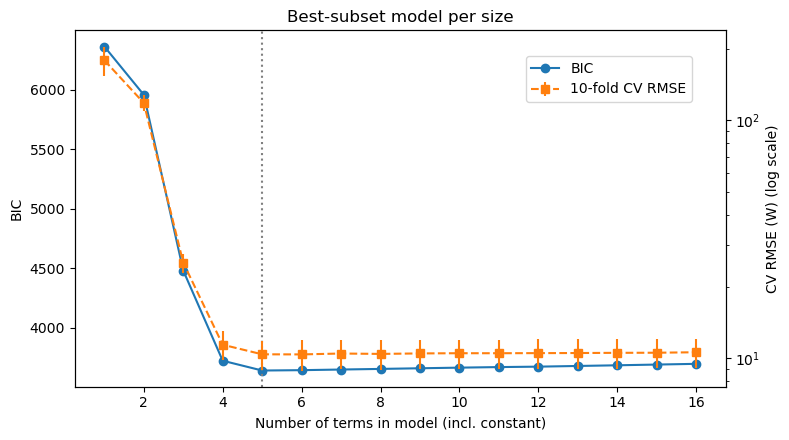

In [9]:
#plot of bic and cv error for the best model of each size, to show why we choose 5 terms
#find the cv column names in the table, whatever brackets they use ([W] or (W))
rmse_col=[c for c in subset_table.columns if c.startswith("CV RMSE")][0]
std_col=[c for c in subset_table.columns if c.startswith("CV std")][0]

fig, ax1=plt.subplots(figsize=(8, 4.5)) #fig-the whole picture; ax1-the drawing area; size 8x4.5 inches
#bic line: x-number of terms (1...16), y-the bic of the best model of that size
ax1.plot(subset_table.index, subset_table["BIC"], "o-", label="BIC") #"o-"-dots joined by a line
ax1.set_xlabel("Number of terms in model (incl. constant)")
ax1.set_ylabel("BIC")
#second y-axis on the right, sharing the same x-axis; bic and cv error have very different numbers
ax2=ax1.twinx()
#cv error line with error bars: yerr-the cv std, how much the error changes between folds
ax2.errorbar(subset_table.index, subset_table[rmse_col], yerr=subset_table[std_col],
             fmt="s--", color="tab:orange", label="10-fold CV RMSE") #"s--"-squares joined by a dashed line
ax2.set_ylabel("CV RMSE (W) (log scale)")
ax2.set_yscale("log") #log scale-the error goes from 179 W down to 10 W; without log the small values look flat
ax1.axvline(best_k, color="grey", linestyle=":") #vertical dotted line at k=5, the model we chose
ax1.set_title("Best-subset model per size")
fig.legend(loc="upper right", bbox_to_anchor=(0.88, 0.88)) #one legend for both lines, inside the top right corner
fig.tight_layout() #fix the spacing so labels are not cut off
fig.savefig("task0_model_selection.png", dpi=150) #save the picture for the report; dpi-quality
plt.show() 

In [10]:
#METHOD 2
#forward stepwise selection: a faster check of best subset; add terms one by one, always the one that helps most
#selected-terms already in the model (starts empty); remaining-terms we can still add (all 16)
#current_bic-bic of the model so far; start with "infinitely bad"
selected, remaining, current_bic=[], list(all_terms), np.inf
#repeat while there are terms left to try
while remaining:
    #try adding each remaining term to the current model, one at a time, and compute the bic
    #scores-a dictionary: term -> bic of the model with that term added
    scores={t: gaussian_bic(X_train[selected+[t]].values, y_train) for t in remaining}
    best_term=min(scores, key=scores.get) #the term that gives the lowest bic
    #if even the best term makes the bic worse (or equal), adding more doesn't help-stop
    if scores[best_term]>=current_bic:
        break
    current_bic=scores[best_term] #remember the new, lower bic
    selected.append(best_term) #put the term in the model
    remaining.remove(best_term) #and take it out of the ones left to try

print("Forward stepwise selection:", [readable_term(t) for t in selected], f"(BIC = {current_bic:.1f})")
#set(...)-ignores the order; checks if both methods picked the same terms
print("Identical to best subset:", set(selected)==set(chosen_terms))

Forward stepwise selection: ['n^3', 'n^2 Q', 'Q^3', '1', 'n Q^2'] (BIC = 3641.7)
Identical to best subset: True


# Methods

### 1. Best subset selection
1. List all possible combinations of the 16 terms: $2^{16}-1 = 65\,535$.
2. Fit a linear regression on each one.
3. Score each with BIC (how badly it fits + a penalty for every term).
4. Keep the combination with the lowest BIC.

- **Pro:** guaranteed to find the best model, because nothing is skipped.
- **Con:** the number of combinations doubles with every extra term, so it's only possible with few features.
- **Result:** $\{1,\ n^3,\ n^2Q,\ nQ^2,\ Q^3\}$, BIC = 3641.7

### 2. Forward stepwise selection
1. Start with no terms.
2. Try adding each remaining term; keep the one that lowers BIC the most.
3. Repeat until no term lowers BIC anymore.

- **Pro:** much faster (about 70 models instead of 65 535).
- **Con:** greedy, because an early choice is never undone, so it can miss the best model.
- **Result:** $\{n^3,\ n^2Q,\ Q^3,\ 1,\ nQ^2\}$, BIC = 3641.7, the same 5 terms as best subset.

### 3. Lasso 
Lasso adds a penalty that pushes the β's of unimportant terms to exactly zero; the penalty strength λ is chosen by cross-validation. It kept 8 terms, because the polynomial features are strongly correlated (near-copies), and Lasso then spreads the weight across similar columns instead of picking the true one.

In [11]:
#lasso: a third way to select terms; the penalty pushes unimportant betas to exactly 0
#take all terms except the constant (n0Q0); lasso adds its own intercept
non_constant_terms=[t for t in all_terms if t!="n0Q0"]
#pipeline-2 steps in one model: first standardise the columns, then lasso
#StandardScaler-every column gets mean 0 and std 1, so the penalty is fair to all terms
#LassoCV-chooses the penalty strength (lambda) by 10-fold cross-validation
#max_iter-how many steps it may take to find the betas (more, because the columns are so correlated)
lasso=make_pipeline(StandardScaler(), LassoCV(cv=10, random_state=RANDOM_SEED, max_iter=200_000))
lasso.fit(X_train[non_constant_terms], y_train) #learn on the training data
#lasso[-1]-the last step of the pipeline (the lasso itself); .coef_-its betas
#put the betas in a list with readable names (n^3, n^2 Q...), 1 decimal
lasso_coefs=pd.Series(lasso[-1].coef_, index=[readable_term(t) for t in non_constant_terms]).round(1)
#alpha_-the lambda that cross-validation chose
print(f"lambda = {lasso[-1].alpha_:.3f}; non-zero standardised coefficients:")
lasso_coefs[lasso_coefs!=0] #show only the terms lasso kept (beta not 0)

lambda = 0.523; non-zero standardised coefficients:


Q^3       -304.4
n Q         60.3
n^2         35.4
n^2 Q      390.8
n^2 Q^3     -3.1
n^3        222.0
n^3 Q      123.2
n^3 Q^3     -7.2
dtype: float64

# The final model and its test errors(4th subtask)

In [12]:
#the function that makes the coefficient table: for each term-beta, how uncertain it is, and if it really matters
def ols_coefficient_table(X_df, y):
    X=X_df.values #the columns of the model as plain numbers
    n_obs, n_params=X.shape #n_obs-rows (480); n_params-number of betas (5)
    coefs, *_=np.linalg.lstsq(X, y, rcond=None) #the betas (least squares); *_ throws the rest away
    residuals=y-X@coefs #the errors: true minus predicted
    #sigma2-how big the noise is: sum of squared errors divided by (rows-betas)
    sigma2=residuals@residuals/(n_obs-n_params)
    #std_errors-how uncertain each beta is; bigger noise or correlated columns-bigger std error
    std_errors=np.sqrt(np.diag(sigma2*np.linalg.inv(X.T@X)))
    t_values=coefs/std_errors #how many std errors the beta is away from 0; far from 0-the term matters
    dof=n_obs-n_params #degrees of freedom: 480-5=475
    #p-value-the chance of a t this large if the real beta were 0; tiny-the term certainly matters
    #2*-we look at both sides (beta could be positive or negative)
    p_values=2*stats.t.sf(np.abs(t_values), dof)
    t_crit=stats.t.ppf(0.975, dof) #about 1.96, the number we need for a 95% interval
    return pd.DataFrame({
        "coef": coefs, "std err": std_errors, "t": t_values,
        #the t-value is the coefficient divided by its standard error; it tells how many times bigger the effect is than its uncertainty. Above about 2 the term clearly matters, and all our five terms have |t| between 9.8 and 210.
        #write the p-value in short form (e.g. 8.9e-21); too small to show-"< 1e-300"
        "p-value": [f"{p:.1e}" if p>=1e-300 else "< 1e-300" for p in p_values],
        #95% confidence interval: beta +- 1.96 std errors; the real beta is in here with 95% confidence
        "95% CI low": coefs-t_crit*std_errors, "95% CI high": coefs+t_crit*std_errors,
    }, index=[readable_term(t) for t in X_df.columns]).round(5) #rows named n^3, n^2 Q...; 5 decimals


#the final model: linear regression with only the 5 chosen terms, on all the training data
final_model=LinearRegression(fit_intercept=False).fit(X_train[chosen_terms], y_train)
#pair each term with its beta: {'n0Q0': 40.86, 'n0Q3': -0.00838, ...}
coefficients=dict(zip(chosen_terms, final_model.coef_))
#write the formula as text: for each term "(beta)*term", all joined with " + ", and "P = " in front
#.4g-show each beta with 4 significant digits (e.g. 7.65782 -> 7.658)
print("P = "+" + ".join(f"({c:.4g})*{readable_term(t)}" for t, c in coefficients.items()))
ols_coefficient_table(X_train[chosen_terms], y_train) 

P = (40.86)*1 + (-0.00838)*Q^3 + (-0.04956)*n Q^2 + (2.407)*n^2 Q + (7.658)*n^3


,coef,std err,t,p-value,95% CI low,95% CI high
1,40.86495,0.76907,53.13572,5.2e-202,39.35376,42.37615
Q^3,-0.00838,0.00028,-30.11713,3.1e-112,-0.00893,-0.00783
n Q^2,-0.04956,0.00506,-9.80077,8.9e-21,-0.05950,-0.03963
n^2 Q,2.40725,0.02584,93.14335,< 1e-300,2.35646,2.45803
n^3,7.65782,0.03644,210.15094,< 1e-300,7.58622,7.72942


In [13]:
#the final test: how good is our model on new data, compared with 2 other models
#model 2: all 16 terms, to compare with our 5-term model
full_model=LinearRegression(fit_intercept=False).fit(X_train, y_train)
#model 3: our 5 terms but without the constant, to check if the constant really belongs
terms_without_constant=[t for t in chosen_terms if t!="n0Q0"] #the 4 terms except "1"
model_without_constant=LinearRegression(fit_intercept=False).fit(X_train[terms_without_constant], y_train)

#predictions of our final 5-term model
train_pred=final_model.predict(X_train[chosen_terms]) #on the data it learned from
test_pred=final_model.predict(X_test[chosen_terms]) #on new data (test1.csv), first and only time we use it

pd.DataFrame({
    "Selected model (train)": error_metrics(y_train, train_pred), #compare with test to check overfitting
    "Selected model (test)": error_metrics(y_test, test_pred), #OUR RESULT for the report
    "All 16 terms (test)": error_metrics(y_test, full_model.predict(X_test)),
    "Selected without constant (test)": error_metrics(y_test, model_without_constant.predict(X_test[terms_without_constant])),
})

,Selected model (train),Selected model (test),All 16 terms (test),Selected without constant (test)
RMSE (W),10.34000,10.36000,10.39000,29.23000
MAE (W),7.80000,8.06000,8.03000,26.79000
Max error (W),48.90000,37.64000,37.89000,60.76000
R^2,0.99965,0.99963,0.99963,0.99705


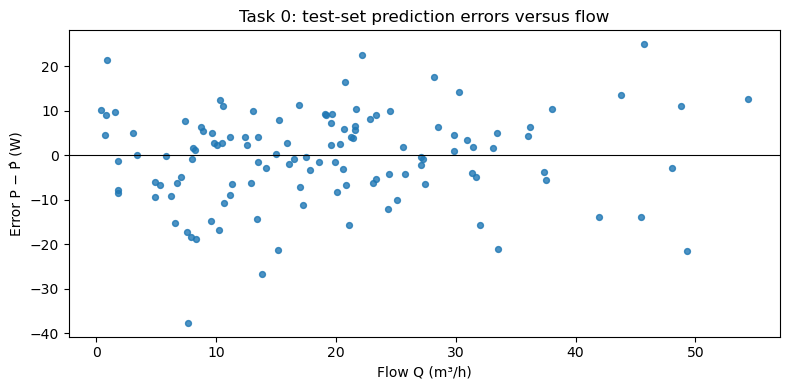

In [14]:
#the plot required by the task: test errors versus flow
test_errors=y_test-test_pred #for each test row: true power minus predicted power
fig, ax=plt.subplots(figsize=(8, 4)) 
#one dot per test row: x-the flow, y-the error of that row
#s-dot size; alpha-a bit see-through, so overlapping dots stay visible
ax.scatter(test["flow_m3_h"], test_errors, s=18, alpha=0.8)
ax.axhline(0, color="black", linewidth=0.8) #horizontal line at 0-a perfect prediction
ax.set_xlabel("Flow Q (m³/h)")
ax.set_ylabel("Error P − P̂ (W)") #P̂ (p-hat)-the predicted power
ax.set_title("Task 0: test-set prediction errors versus flow")
fig.tight_layout() #fix the spacing so labels are not cut off
fig.savefig("task0_errors_vs_flow.png", dpi=150) 
plt.show() 